In [121]:
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten , Input

import matplotlib.pyplot as plt

In [3]:
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

In [4]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
X_test.shape

(10000, 28, 28)

In [6]:
y_train.shape

(60000,)

In [7]:
y_test.shape

(10000,)

In [8]:
X_train[0].shape

(28, 28)

In [10]:
X_train[0]  # 0 - Black 255 - white

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

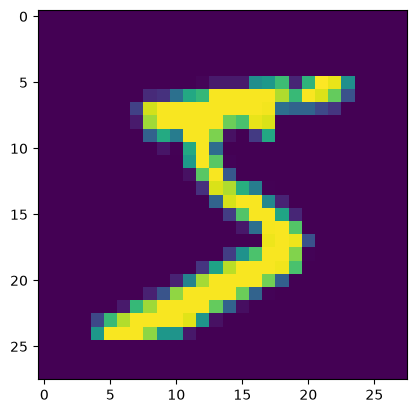

In [13]:
plt.imshow(X_train[0] )

In [15]:
print(y_train[0])

5


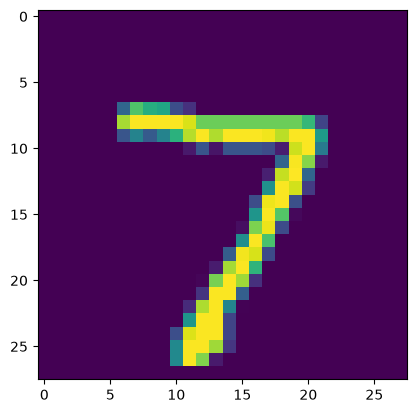

In [16]:
plt.imshow(X_test[0] )

In [17]:
print(y_test[0])

7


In [18]:
X_train = X_train / 255
X_test = X_test / 255

In [19]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [126]:
model = Sequential()

In [127]:
model.add(Input(shape=(28, 28)))
model.add(Flatten())
model.add(Dense(100, activation='relu'))
model.add(Dense(50, activation='relu'))
model.add(Dense(10, activation='softmax'))

In [128]:
28 * 28

784

In [131]:
model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,060 (328.36 KB)

 Trainable params: 84,060 (328.36 KB)

 Non-trainable params: 0 (0.00 B)

In [132]:
784 * 128 + 128

100480

In [133]:
128 * 10 + 10

1290

In [134]:
100480 + 1290

101770

In [135]:
model.compile(optimizer='adam', loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])

In [136]:
history = model.fit(X_train,y_train,batch_size=50,epochs=100,validation_split=0.2,verbose=1)

Epoch 1/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 804us/step - accuracy: 0.9094 - loss: 0.3127 - val_accuracy: 0.9553 - val_loss: 0.1509
Epoch 2/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 743us/step - accuracy: 0.9603 - loss: 0.1304 - val_accuracy: 0.9639 - val_loss: 0.1237
Epoch 3/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 744us/step - accuracy: 0.9707 - loss: 0.0941 - val_accuracy: 0.9672 - val_loss: 0.1057
Epoch 4/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 720us/step - accuracy: 0.9789 - loss: 0.0686 - val_accuracy: 0.9723 - val_loss: 0.0944
Epoch 5/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 743us/step - accuracy: 0.9826 - loss: 0.0564 - val_accuracy: 0.9724 - val_loss: 0.0953
Epoch 6/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 754us/step - accuracy: 0.9856 - loss: 0.0455 - val_accuracy: 0.9717 - val_loss: 0.1068
Epoch 7/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 763us/step - accuracy: 0.9882 - loss: 0.0370 - val_accuracy: 0.9737 - val_loss: 0.0943
Epoch 8/100
960/960 ━━━━━━━━━━━━━━━━━━━━ 1s 768us/step - accuracy: 0.9910 - loss: 0

In [137]:
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step - accuracy: 0.9772 - loss: 0.2626


[0.2625531852245331, 0.9771999716758728]

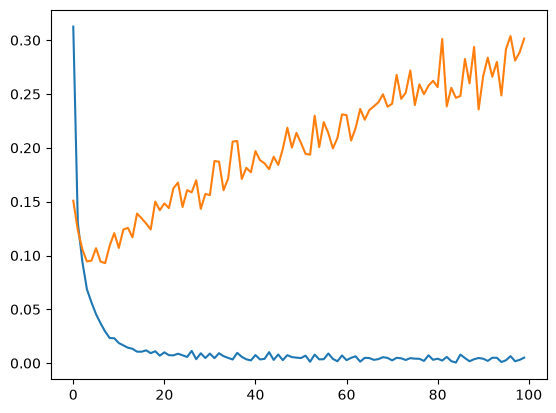

In [138]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

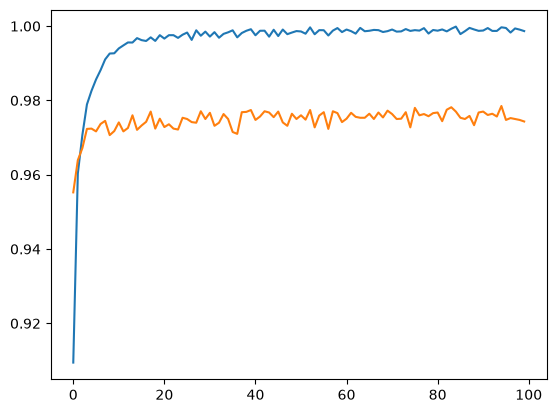

In [139]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [140]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 291us/step


In [141]:
y_pred.shape

(10000, 10)

In [142]:
y_pred_classes = np.argmax(y_pred, axis=1)


accuracy = accuracy_score(y_test, y_pred_classes)
print("Accuracy:", accuracy)

Accuracy: 0.9772


In [143]:
y_pred_classes

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

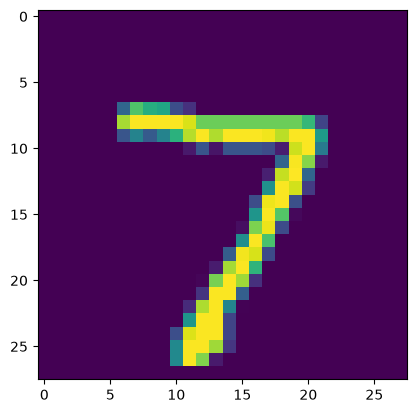

In [144]:
plt.imshow(X_test[0])

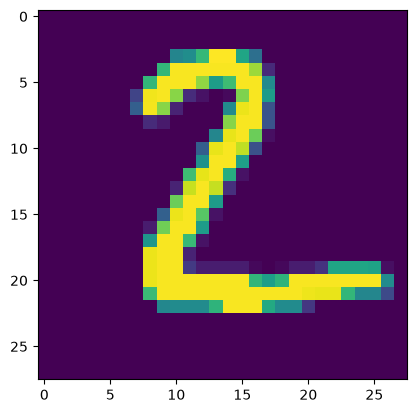

In [145]:
plt.imshow(X_test[1])